In [132]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import PoissonRegressor
import pandas as pd
from sklearn.metrics import mean_poisson_deviance
import matplotlib.pyplot as plt

# Data Preprocessing

Split features and target variables.

In [111]:
raw_df = pd.read_csv("telematics_syn-032021.csv")
X = raw_df.drop(columns=['NB_Claim', 'AMT_Claim'])
y_num = raw_df['NB_Claim']
y_amt = raw_df['AMT_Claim']

print(f"raw_df shape: {raw_df.shape}")
print(f"X shape: {X.shape}")

raw_df shape: (100000, 52)
X shape: (100000, 50)


Split features into categories.

In [112]:
traditional_features = X[['Duration', 'Insured.age', 'Insured.sex', 'Car.age', 'Marital',
       'Car.use', 'Credit.score', 'Region', 'Annual.miles.drive',
       'Years.noclaims', 'Territory']]
telematics_features = X.drop(columns=traditional_features)

A quick check to ensure no columns are left out.

In [113]:
assert len(traditional_features.columns) + len(telematics_features.columns) == len(X.columns), "Feature split does not match original feature count"

Check what encoder I should used based on the categorical data.

In [114]:
traditional_cat_mask = traditional_features.dtypes == object
traditional_cat_columns =  list(traditional_features.columns[traditional_cat_mask])
for i in traditional_cat_columns:
    print(traditional_features[i].unique())

['Male' 'Female']
['Married' 'Single']
['Commute' 'Private' 'Commercial' 'Farmer']
['Urban' 'Rural']


Even though the object type is integer for Territory, it is actually a categorical variable.

In [115]:
traditional_cat_columns.append('Territory')

Split the data

In [123]:
X_train, X_test, y_train, y_test = train_test_split(traditional_features, y_num, test_size=0.2, random_state=42, stratify=y_num)

Given that the categorical variable above consists of categories without any inherent order or ranking. I decided to use one-hot encoder.

In [124]:
ohe = OneHotEncoder(drop='first', sparse_output=False)
cat_train_encoded = ohe.fit_transform(X_train[traditional_cat_columns])
cat_test_encoded = ohe.transform(X_test[traditional_cat_columns])

cat_cols_out = ohe.get_feature_names_out(traditional_cat_columns)

X_train[cat_cols_out] = cat_train_encoded
X_test[cat_cols_out] = cat_test_encoded

X_train = X_train.drop(columns=traditional_cat_columns)
X_test = X_test.drop(columns=traditional_cat_columns)

exposure_train = X_train['Duration']/365.25
exposure_test = X_test['Duration']/365.25

X_train = X_train.drop(columns=['Duration'])
X_test = X_test.drop(columns=['Duration'])

In [126]:
numeric_cols = ["Insured.age", "Car.age", "Credit.score", "Annual.miles.drive", "Years.noclaims"]

scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

In [127]:
print(X_train.shape, X_test.shape)
print(list(X_train.columns) == list(X_test.columns))

(80000, 65) (20000, 65)
True


In [128]:
model = PoissonRegressor(alpha=0.0)
model.fit(X_train, y_train/exposure_train, sample_weight=exposure_train)
y_pred = model.predict(X_test)
model_score = model.score(X_test, y_test/exposure_test, sample_weight=exposure_test)
print(f"Model score: {model_score}")
print(f"predicted claims: {(y_pred)[:5]}")
print(f"Model coefficients: {model.coef_}")
print(f"Number of iterations: {model.n_iter_}")   # how many iterations it actually ran

Model score: 0.03439473295760909
predicted claims: [0.04267468 0.05675002 0.04690389 0.03269578 0.05249697]
Model coefficients: [ 0.05736801 -0.28145045 -0.24593616  0.11464998 -0.17641485 -0.03829621
  0.02753089 -0.08723958 -0.2360786  -0.05242266  0.0909491  -0.18512738
  0.08098151  0.03903798  0.04288095 -0.03474187 -0.16177271 -0.15823354
  0.22969245 -0.01911011 -0.17713106  0.10464766  0.02348665 -0.09834537
  0.06151169 -0.13875817 -0.16924577  0.06938621  0.15507438 -0.07424459
  0.18903917  0.33165884  0.01532918  0.12213479  0.03695791  0.03485119
  0.02553569  0.00867348 -0.20714054  0.02669785 -0.20244009  0.1039716
  0.20082986  0.03587548  0.34237574  0.20158555  0.02655248  0.00555252
 -0.00770414  0.31776174  0.04110026  0.00937211 -0.02879703 -0.07074255
 -0.11555348  0.01752404  0.04865341 -0.10939479 -0.32154276 -0.20970432
 -0.22548576  0.04130031 -0.29283634 -0.08270941  0.02355163]
Number of iterations: 17


In [129]:
deviance = mean_poisson_deviance(
    y_test / exposure_test,   # actual claim rate (same unit y_pred is in)
    y_pred,                   # your model's predicted rate
    sample_weight=exposure_test
)
print(f"Mean Poisson deviance: {deviance}")

Mean Poisson deviance: 0.3117137234358598


20000
19871


/var/folders/v_/3rx_jnys7wb2_zt50m4fwqzh0000gn/T/ipykernel_71211/580909930.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  lift = results.groupby("decile").apply(


(array([4., 3., 1., 2.]),
 array([0.01415413, 0.03595707, 0.05776   , 0.07956294, 0.10136588]),
 <BarContainer object of 4 artists>)

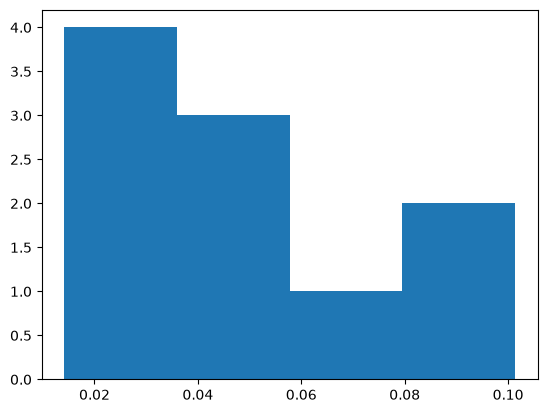

In [136]:
# Step 1: put your predictions and real outcomes side by side
results = pd.DataFrame({
    "predicted_rate": y_pred,           # your model's guess for each policy
    "actual_claims": y_test.values,     # what actually happened
    "exposure": exposure_test.values    # how long that policy was observed
})
print(len(results))
print(results["predicted_rate"].nunique())
# Step 2: sort everyone into 10 lines, based on predicted risk
results["decile"] = pd.qcut(results["predicted_rate"].rank(method="first"), 10, labels=False)
# Step 3: for each line, check what actually happened
lift = results.groupby("decile").apply(
    lambda g: g["actual_claims"].sum() / g["exposure"].sum()
)

plt.hist(lift, bins=4)

# Summary
Things that I have done to fix the model:
1. set the alpha to zero
2. encode all category columns to dummy variables including territory which appears to be integer value column
3. take out duration from features and make it as sample weight.
4. the ultimate issue is that the number of incident claim/duration is very small and probably lower than tolerance. thus, iteration stop at 1. 